<a href="https://colab.research.google.com/github/MhiyaJ/My-GIS-Stuff/blob/main/CCHSDistrict_(PS4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **AFTER SCHOOL PROGRAMS, ACCESIBILITY AND SOCIAL DISENGAGMENT**
By, Mhiya Williams

### **IMPORT LIBRARY, SET-UP DATA FRAME**

Source: theaok.github.io/gisPy/, map.ipynb, Retrieved October 20, 2026

In [1]:
%%capture

import os, zipfile
import pandas as pd #
import matplotlib.pyplot as plt

import geopandas as gpd
from shapely.geometry import Point

import mapclassify

import seaborn as sns

import folium
from folium.plugins import MarkerCluster

from matplotlib.patches import Ellipse

from matplotlib.patheffects import withStroke

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from google.colab import files

from geopandas.tools import geocode

from google.colab.data_table import DataTable
DataTable.max_columns = 250

gpd.__version__

REGIONAL SCHOOL DISTRICT (Secondary)

Black Horse Pike Regional -

Eastern Camden County Regional -

Sterling Regional -

In [2]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Secondary_-5568767075062576326.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njrhs = gpd.read_file('School_Districts_Secondary.shp')

njhighschools.zip		School_Districts_Secondary.prj
sample_data			School_Districts_Secondary.shp
School_Districts_Secondary.cpg	School_Districts_Secondary.shp.xml
School_Districts_Secondary.dbf	School_Districts_Secondary.shx


In [5]:
#Googled - Splitting columns into 2, Option 3: Split text and numbers using Regular Expressions
njrhs["NJDOE_ID_S"] = njrhs["NJDOE_ID_S"].astype(str)
njrhs[["CountyCode", "DistrictCode"]] = njrhs["NJDOE_ID_S"].str.extract(r"(\d{2}).*(\d{4})")

#new columns, DistrictCode and CountyCode, with County Code only including Camden County
njrhs2 = njrhs[njrhs['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID', 'geometry']]
njrhs2['DistrictCode']=njrhs2.DistrictCode.str.strip()

njrhs2.rename(columns={'DIST_NAME' : 'District'}, inplace=True)
njrhs2['District'] = njrhs2['District'].str.upper()
njrhs2["District"] = njrhs2["District"].str.replace(" REGIONAL SCHOOL DISTRICT", "")

njrhs2

,DistrictCode,CountyCode,District,GEOID,geometry
20,5035,07,STERLING,3402880,"POLYGON ((342322.53 375467.11, 345610.5 373541..."
40,0390,07,BLACK HORSE PIKE,3401770,"POLYGON ((322014.45 380972.53, 321992.84 38092..."
42,1255,07,EASTERN CAMDEN COUNTY,3404380,"MULTIPOLYGON (((367503.372 354073.834, 370576...."


PRIMARY SCHOOL DISTRICT

In [7]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Unified_7341673536716239500.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njsch = gpd.read_file('School_Districts_Unified.shp')

njhighschools.zip		    School_Districts_Secondary.shx
sample_data			    School_Districts_Unified.cpg
School_Districts_Secondary.cpg	    School_Districts_Unified.dbf
School_Districts_Secondary.dbf	    School_Districts_Unified.prj
School_Districts_Secondary.prj	    School_Districts_Unified.shp
School_Districts_Secondary.shp	    School_Districts_Unified.shp.xml
School_Districts_Secondary.shp.xml  School_Districts_Unified.shx


In [10]:
#Googled - Splitting columns into 2, Option 3: Split text and numbers using Regular Expressions
njsch["NJDOE_ID_U"] = njsch["NJDOE_ID_U"].astype(str)
njsch[["CountyCode", "DistrictCode"]] = njsch["NJDOE_ID_U"].str.extract(r"(\d{2}).*(\d{4})")

#new columns, DistrictCode and CountyCode, with County Code only including Camden County
njsch2=njsch[njsch['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID','geometry']]
njsch2['DistrictCode']=njsch2.DistrictCode.str.strip()

njsch2.rename(columns={'DIST_NAME' : 'District'}, inplace=True)
njsch2['District'] = njsch2['District'].str.upper()
njsch2['District'] = njsch2['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
njsch2['District'] = njsch2['District'].str.replace("LAWNSIDE SCHOOL DISTRIC", "LAWNSIDE SCHOOL DISTRICT")
njsch2["District"] = njsch2["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
njsch2["District"] = njsch2["District"].str.replace(" SCHOOL DISTRICT", "")
njsch2["District"] = njsch2["District"].str.replace(" BOARD OF EDUCATION", "")

njsch2

,DistrictCode,CountyCode,District,GEOID,geometry
34,5820,07,WINSLOW TOWNSHIP,3418060,"POLYGON ((368609.977 344389.586, 368631.27 344..."
41,0150,07,AUDUBON,3401050,"POLYGON ((333599.519 389532.256, 334908.018 38..."
43,0940,07,COLLINGSWOOD,3403420,"POLYGON ((329936.77 398206.61, 330020.49 39819..."
50,1880,07,HADDON HEIGHTS,3406330,"POLYGON ((338431.442 383843.61, 338435.82 3836..."
51,2130,07,HI NELLA,3407080,"POLYGON ((346458.121 367972.644, 346568.817 36..."
52,3770,07,OAKLYN,3411940,"POLYGON ((331980.807 391389.812, 331778.88 391..."
53,0800,07,CHERRY HILL,3403000,"POLYGON ((347458.19 406942.14, 347464.79 40692..."
54,1900,07,HADDONFIELD,3406390,"POLYGON ((341402.77 394798.54, 341480.9 394783..."
58,4110,07,PINE HILL,3412990,"POLYGON ((351592.589 354425.759, 351577.79 351..."
59,1890,07,HADDON TOWNSHIP,3406360,"MULTIPOLYGON (((325315.69 389559.475, 325405.0..."


SCHOOL DISTRICT MAP

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(345312.7528761769, 367625.19875515526, 'STERLING')

Text(338920.12994010805, 354312.48226620577, 'BLACK HORSE PIKE')

Text(365020.87346082885, 364203.57128416805, 'EASTERN')

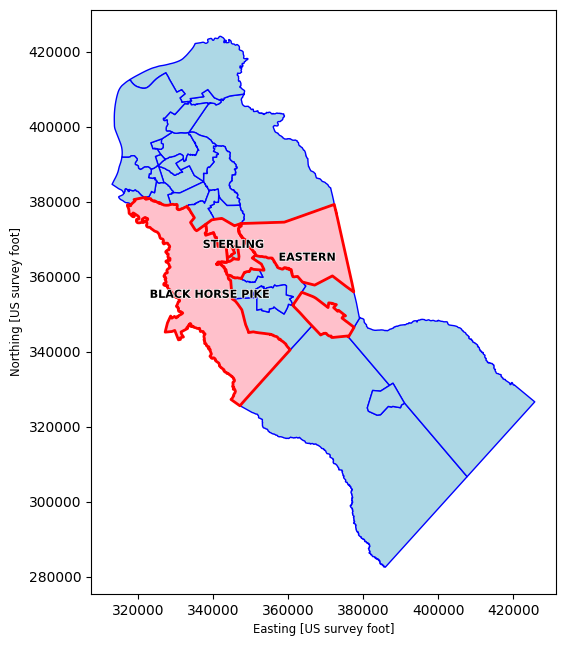

In [12]:
fig, ax = plt.subplots(1, figsize=(6,10))
njsch2.plot(ax=ax,edgecolor='blue', color = 'lightblue', linewidth=1)
njrhs2.plot (ax=ax, edgecolor='red', color = 'pink', linewidth=2)

for x, y, label in zip(njrhs2.geometry.centroid.x, njrhs2.geometry.centroid.y, njrhs2.District):
    #Keep label names brief by stripping common suffixes to reduce overlap further
    label = label.replace(" BOROUGH", "").replace(" TOWNSHIP", "").replace(" CAMDEN COUNTY", "")
    ax.annotate(label, xy=(x, y),horizontalalignment='center',
    fontsize=8,color='black', fontweight='bold',
    path_effects=[withStroke(linewidth=1, foreground='white')]) #ytext=(3, 3), textcoords="offset points"


MUNICIPALITY SHAPEFILE

In [13]:
!wget -q -O Muni.zip  https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Municipalities.zip
zip_ref = zipfile.ZipFile('Muni.zip', 'r');zip_ref.extractall(); zip_ref.close()

Muni = gpd.read_file('Municipalities.shp')

In [16]:
Muni.rename(columns={'NAMELSAD' : 'Muni'}, inplace=True)
Muni['Muni'] = Muni['Muni'].str.upper()
Muni.loc[Muni['Muni'] == 'GLOUCESTER CITY CITY','Muni'] = 'GLOUCESTER CITY'

Muni [['GEOID', 'Muni', 'geometry' ]]

,GEOID,Muni,geometry
0,3400702200,AUDUBON BOROUGH,"POLYGON ((495599.23 4415536.249, 495508.749 44..."
1,3400702230,AUDUBON PARK BOROUGH,"POLYGON ((492866.221 4416337.872, 492855.687 4..."
2,3400703250,BARRINGTON BOROUGH,"POLYGON ((496819.374 4414558.505, 496827.878 4..."
3,3400704750,BELLMAWR BOROUGH,"POLYGON ((492951.896 4413667.751, 492968.147 4..."
4,3400705440,BERLIN BOROUGH,"POLYGON ((507881.319 4403761.193, 507873.371 4..."
5,3400705470,BERLIN TOWNSHIP,"POLYGON ((507848.567 4406644.366, 507978.687 4..."
6,3400708170,BROOKLAWN BOROUGH,"POLYGON ((490740.818 4414218.502, 490736.285 4..."
7,3400710000,CAMDEN CITY,"POLYGON ((493032.266 4419551.728, 492897.768 4..."
8,3400712280,CHERRY HILL TOWNSHIP,"POLYGON ((506224.674 4413748.279, 506174.32 44..."
9,3400712550,CHESILHURST BOROUGH,"POLYGON ((512006.451 4397643.342, 512016.246 4..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

Text(1, 1, 'AUDUBON')

Text(1, 1, 'AUDUBON PARK')

Text(1, 1, 'BARRINGTON')

Text(1, 1, 'BELLMAWR')

Text(1, 1, 'BERLIN')

... (27 outputs left out)

Text(1, 1, 'VOORHEES')

Text(1, 1, 'WATERFORD')

Text(1, 1, 'WINSLOW')

Text(1, 1, 'WOODLYNNE')

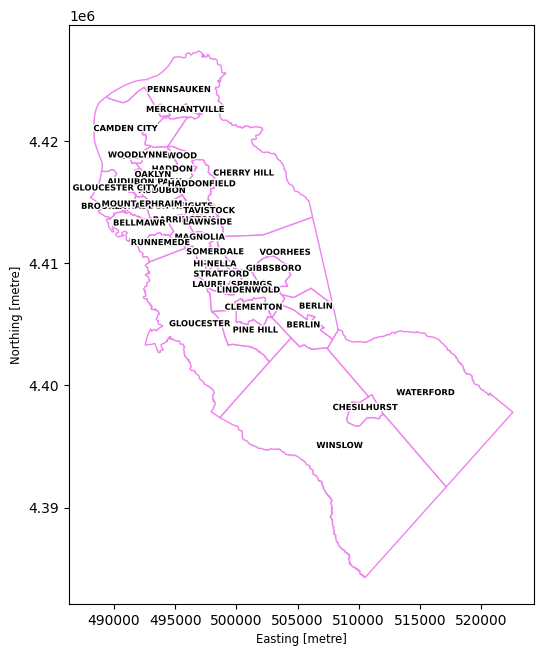

In [17]:
fig, ax = plt.subplots(1, figsize=(6,10))
Muni.plot(ax=ax,edgecolor='violet', color = 'white', linewidth=1)

for x, y, label in zip(Muni.geometry.centroid.x, Muni.geometry.centroid.y, Muni.Muni):
    #Keep label names brief by stripping common suffixes to reduce overlap further
    label = label.replace(" BOROUGH", "").replace(" TOWNSHIP", "")
    ax.annotate(label, xy=(x, y),horizontalalignment='center',
    fontsize=6,color='black', fontweight='bold',
    path_effects=[withStroke(linewidth=2, foreground='white')], xytext=(1, 1), textcoords="offset points")

MEDIAN HOUSEHOLD INCOME

In [18]:
#Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Inflation Adjusted Dollars), 2024. Prepared by Social Explorer. https://www.socialexplorer.com/data/ACS2024_5yr/metadata?ds=SE&table=A14006 (accessed 27 September 2026 at 10:01:00 GMT-4).
IncXls = pd.read_excel('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Median%20Household%20Income.xlsx', header=3, nrows=36)

In [20]:
#Rename columns, make everything upper case and clear white space.  Also remove Camden County, New Jersey with white space, #take extra city out Gloucester
#Filter for both only to show 2024-2025 SchoolYear and Camden
IncXls1=IncXls[['SE:A14006:Median Household Income (In 2024 Inflation Adjusted Dollars)','Unnamed: 1']]
IncXls1.rename(columns={'SE:A14006:Median Household Income (In 2024 Inflation Adjusted Dollars)': 'Muni'}, inplace=True)
IncXls1.rename(columns={'Unnamed: 1': 'Median Income'}, inplace=True)
IncXls1['Muni'] = IncXls1['Muni'].str.upper()
IncXls1['Muni'] = IncXls1['Muni'].str.replace(', CAMDEN COUNTY, NEW JERSEY', '', regex=False).str.strip()
IncXls1.loc[IncXls1['Muni'] == 'GLOUCESTER CITY CITY','Muni'] = 'GLOUCESTER CITY'
IncXls1

,Muni,Median Income
0,AUDUBON BOROUGH,115789
1,AUDUBON PARK BOROUGH,56619
2,BARRINGTON BOROUGH,87290
3,BELLMAWR BOROUGH,76654
4,BERLIN BOROUGH,102855
5,BERLIN TOWNSHIP,75238
6,BROOKLAWN BOROUGH,59063
7,CAMDEN CITY,40546
8,CHERRY HILL TOWNSHIP,121502
9,CHESILHURST BOROUGH,91683


In [22]:
#convert column to float
#IncXls1['Median Income'] = IncXls1.Median_Income.astype(float)
#did not run, explained error via Gemini, resulted in new code.
IncXls1['Median Income'] = pd.to_numeric(IncXls1['Median Income'], errors='coerce')

In [23]:
#Regular merge on Muni, no first word separation needed
I1 = pd.merge(Muni, IncXls1, on='Muni', how='outer', indicator=True)
I1

,FID,COUSUBNS,GEOID,Muni,CLASSFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,GEOCODE,GlobalID,Shape__Are,Shape__Len,geometry,Median Income,_merge
0,1,00885144,3400702200,AUDUBON BOROUGH,C5,F,3838781,35535,+39.8901277,-75.0723825,9407.757950,3400702200,81d661c6-35a7-42ed-8afd-5f35d0b0e807,3.871214e+06,9407.757866,"POLYGON ((495599.23 4415536.249, 495508.749 44...",115789.0,both
1,2,00885145,3400702230,AUDUBON PARK BOROUGH,C5,F,389606,46935,+39.8968373,-75.0888190,2734.677596,3400702230,f8ccbea8-76dd-44e7-992b-e367d22e31a1,4.361934e+05,2734.677499,"POLYGON ((492866.221 4416337.872, 492855.687 4...",56619.0,both
2,3,00885149,3400703250,BARRINGTON BOROUGH,C5,F,4095340,0,+39.8689349,-75.0513618,11456.984021,3400703250,9e9086b1-16e4-429f-b5c4-d967de1dbd82,4.092067e+06,11456.984073,"POLYGON ((496819.374 4414558.505, 496827.878 4...",87290.0,both
3,4,00885154,3400704750,BELLMAWR BOROUGH,C5,F,7729295,315734,+39.8663560,-75.0946695,18085.471872,3400704750,bdd07346-3ee8-471e-befd-b8b9e16eb0a9,8.038608e+06,18085.472003,"POLYGON ((492951.896 4413667.751, 492968.147 4...",76654.0,both
4,5,00885158,3400705440,BERLIN BOROUGH,C5,F,9307767,35573,+39.7920594,-74.9369855,14823.777678,3400705440,032f4608-e579-4343-a5e1-7d3778ce56c5,9.335884e+06,14823.777540,"POLYGON ((507881.319 4403761.193, 507873.371 4...",102855.0,both
5,6,00882152,3400705470,BERLIN TOWNSHIP,T1,A,8656740,15360,+39.8071159,-74.9241780,15771.555136,3400705470,e17a4101-16d7-4093-b9da-43f1044ceef7,8.665170e+06,15771.555122,"POLYGON ((507848.567 4406644.366, 507978.687 4...",75238.0,both
6,7,00885172,3400708170,BROOKLAWN BOROUGH,C5,F,1265110,105763,+39.8793503,-75.1203958,5697.800517,3400708170,1e1a2ee3-3807-458d-8af0-7a2d5df7de30,1.369780e+06,5697.800436,"POLYGON ((490740.818 4414218.502, 490736.285 4...",59063.0,both
7,8,00885177,3400710000,CAMDEN CITY,C5,F,23106182,3676392,+39.9367868,-75.1066438,28004.054276,3400710000,f5c8c982-1593-4592-a38a-485a23bd7d98,2.676122e+07,28004.054367,"POLYGON ((493032.266 4419551.728, 492897.768 4...",40546.0,both
8,9,00882155,3400712280,CHERRY HILL TOWNSHIP,T1,A,62346260,321495,+39.9046107,-74.9969997,42634.513569,3400712280,561f8439-f9d9-47af-a877-f4c81e30fd7a,6.261764e+07,42634.513259,"POLYGON ((506224.674 4413748.279, 506174.32 44...",121502.0,both
9,10,00885183,3400712550,CHESILHURST BOROUGH,C5,F,4442825,4000,+39.7297952,-74.8805311,9002.409548,3400712550,db06a511-84e0-41f6-a5d9-e8afa47e852f,4.443282e+06,9002.409554,"POLYGON ((512006.451 4397643.342, 512016.246 4...",91683.0,both


MAP OF MEDIAN INCOME

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

[]

[]

Text(0.5, 80.7222222222222, 'Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Inflation Adjusted Dollars)')

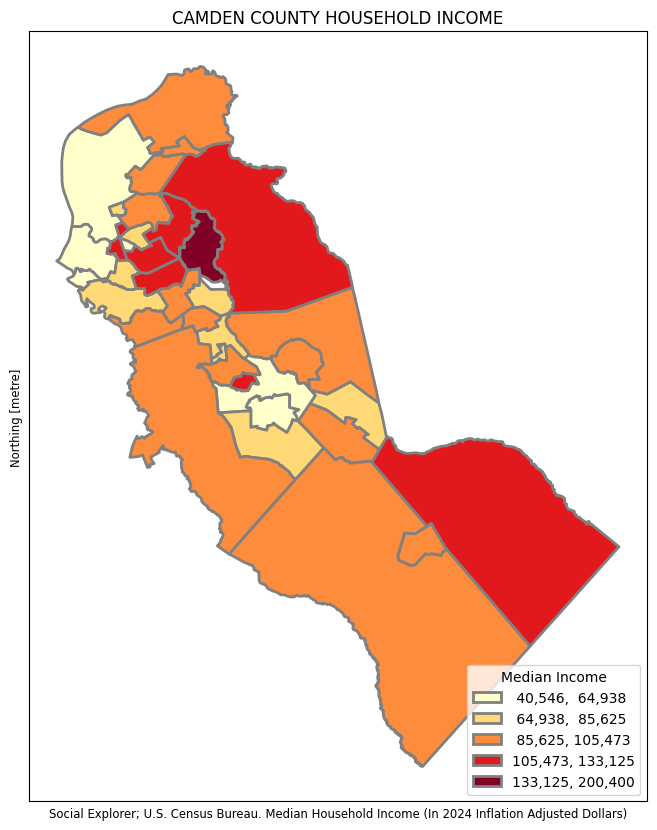

In [24]:
#fig, ax = plt.subplots(1, figsize=(6,10))
#a1.plot(ax=ax,column='Median Income',legend=True,cmap='YlOrRd',
#         scheme='natural_breaks',k=5, edgecolor='grey',linewidth=2,
#          legend_kwds= {"fmt": "{'bins':[40000, 75000, 125000,]}",'loc':'lower right','markerscale':1.4})
#leg1 = ax.get_legend()
#leg1.set_title('''Median Income''')
#ax.title.set_text("CAMDEN COUNTY HOUSEHOLD INCOME")
#ax.set_xticks([]) #kills xticks
#ax.set_yticks([]) #kills xticks
#ax.set_xlabel('''Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Inflation Adjusted Dollars)''')

#code above didn't run, requested Gemini to explain error

fig, ax = plt.subplots(1, figsize=(8,10))
I1.plot(ax=ax,column='Median Income',legend=True,cmap='YlOrRd',
          scheme='natural_breaks',
          k=5,
          edgecolor='grey',linewidth=2,
          legend_kwds= {"fmt": "{:,.0f}", 'loc':'lower right', 'markerscale':1.4})
leg1 = ax.get_legend()
if leg1 is not None:
    leg1.set_title('''Median Income''')
ax.title.set_text("CAMDEN COUNTY HOUSEHOLD INCOME")
ax.set_xticks([]) #kills xticks
ax.set_yticks([]) #kills xticks
ax.set_xlabel('''Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Inflation Adjusted Dollars)''')

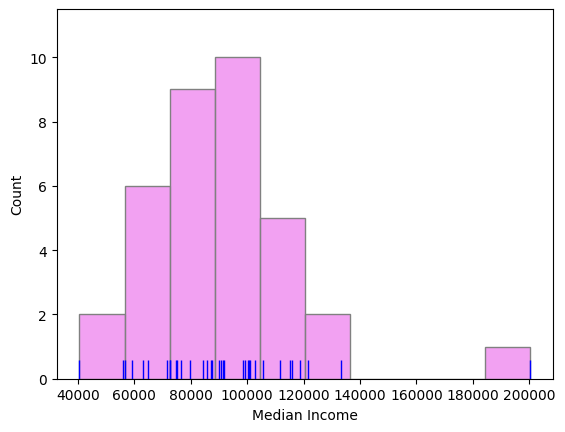

In [25]:
ax = sns.histplot(IncXls1["Median Income"], color="violet", edgecolor="grey", linewidth= 1, bins=10) #one more bin than obs
sns.rugplot(IncXls1["Median Income"], height=0.05, color="blue", ax=ax);

SIDE BY SIDE MEDIAN INCOME MAPS W/ BINS CHANGES

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

[]

[]

Text(0.5, 181.94675068213658, 'Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Dollars)')

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

[]

... (2 outputs left out)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

[]

[]

Text(0.5, 181.94675068213658, 'Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Dollars)')

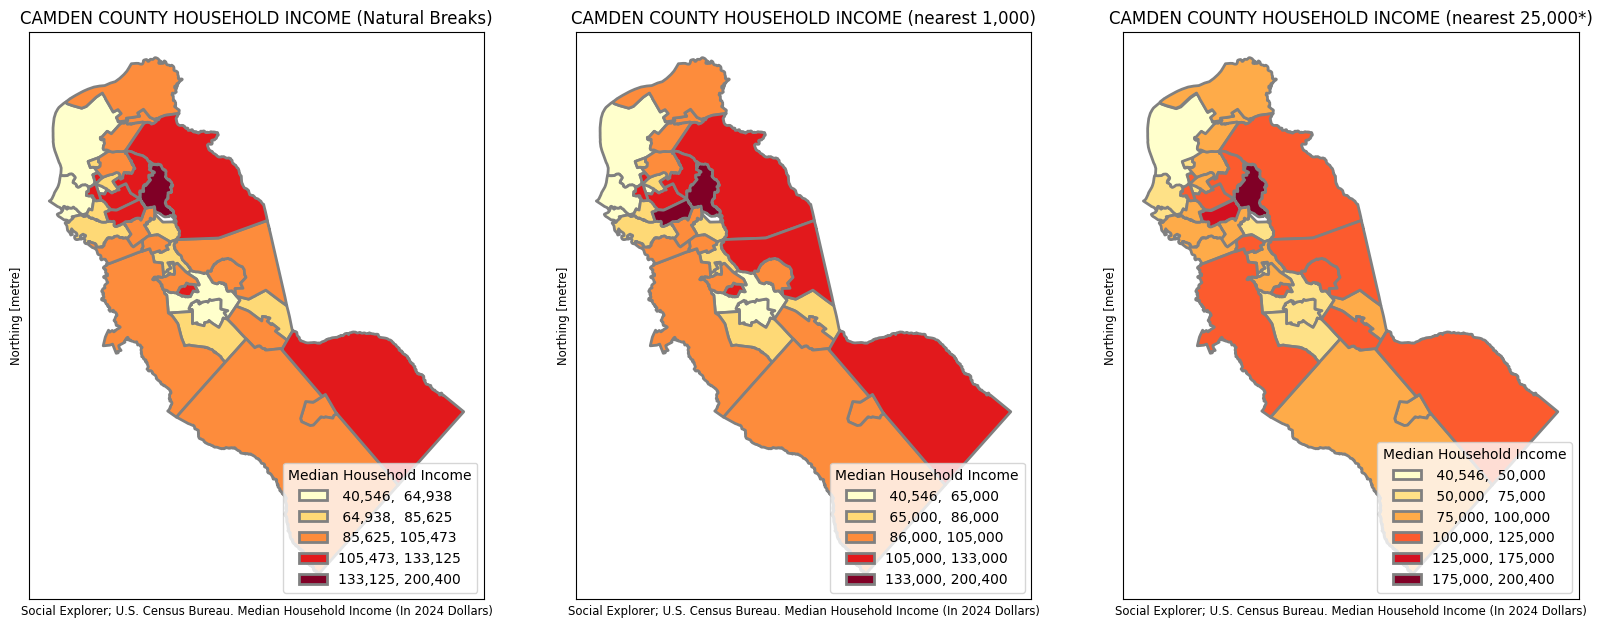

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(20, 10))

# Left plot (Natural Breaks)
I1.plot(ax=axs[0], column='Median Income', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='grey', linewidth=2,
        legend_kwds={"fmt": "{:,.0f}", 'loc': 'lower right', 'markerscale': 1.4})

leg0 = axs[0].get_legend()
if leg0 is not None:
    leg0.set_title("Median Household Income")
axs[0].title.set_text("CAMDEN COUNTY HOUSEHOLD INCOME (Natural Breaks)")
axs[0].set_xticks([])
axs[0].set_yticks([])
axs[0].set_xlabel("Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Dollars)")

# Middle plot (User Defined Breaks)
I1.plot(ax=axs[1], column='Median Income', legend=True, cmap='YlOrRd',
        scheme='UserDefined',
        classification_kwds={'bins': [65000, 86000, 105000, 133000]},
        edgecolor='grey', linewidth=2,
        legend_kwds={"fmt": "{:,.0f}", 'loc': 'lower right', 'markerscale': 1.4})

leg1 = axs[1].get_legend()
if leg1 is not None:
    leg1.set_title("Median Household Income")
axs[1].title.set_text("CAMDEN COUNTY HOUSEHOLD INCOME (nearest 1,000)")
axs[1].set_xticks([])
axs[1].set_yticks([])
axs[1].set_xlabel("Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Dollars)")

I1.plot(ax=axs[2], column='Median Income', legend=True, cmap='YlOrRd',
          scheme='UserDefined',
          classification_kwds={'bins': [50000, 75000, 100000, 125000, 175000]},
          edgecolor='grey',linewidth=2,
          legend_kwds= {"fmt": "{:,.0f}",'loc':'lower right','markerscale':1.4})

leg2 = axs[2].get_legend()
if leg2 is not None:
    leg2.set_title("Median Household Income")
axs[2].title.set_text("CAMDEN COUNTY HOUSEHOLD INCOME (nearest 25,000*)")
axs[2].set_xticks([])
axs[2].set_yticks([])
axs[2].set_xlabel("Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Dollars)")

Explain why change in bins and what municipalities are higher than others

OVERLAY MAP OF MEDIAN INCOME AND SCHOOL DISTRICTS

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

[]

[]

(np.float64(486316.5315953321),
 np.float64(524333.1014980257),
 np.float64(4382143.984544183),
 np.float64(4429505.6737721525))

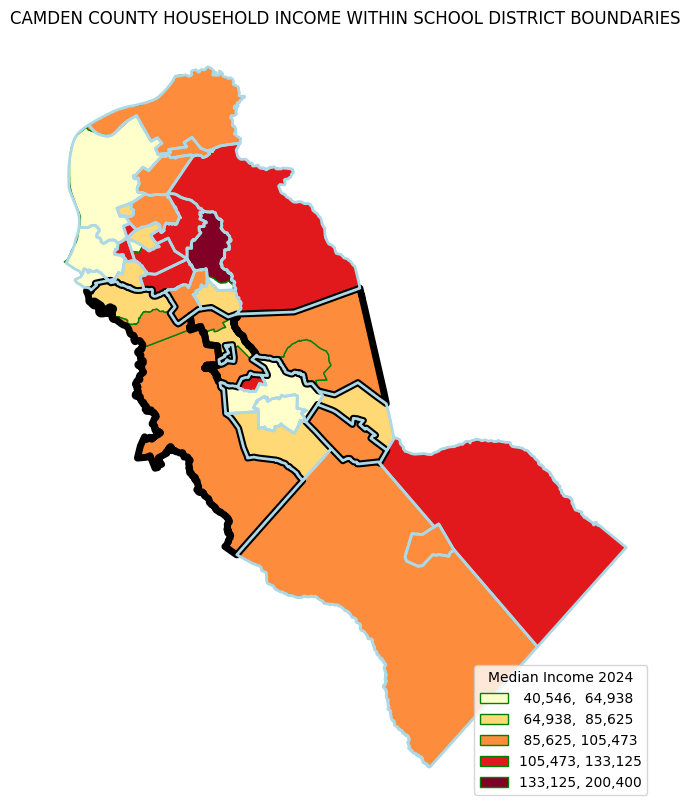

In [89]:
#fig, ax = plt.subplots(1, figsize=(8, 10))
#a1.plot(ax=ax, column='Median Income', legend=True, cmap='YlOrRd',
#        scheme='natural_breaks', k=5, edgecolor='grey', linewidth=2,
#        legend_kwds={"fmt": "{:,.0f}", 'loc': 'lower right', 'markerscale': 1.4})
#leg1 = ax.get_legend()
#leg1.set_title('''Median Income 2024''')

#njrhs2.plot(ax=ax, color='none', edgecolor='red', linewidth=1.5, label='Secondary School Districts')
#njsch2.plot(ax=ax, color='none', edgecolor='blue', linewidth=1.5, label='Unified School Districts')

#ax.title.set_text("CAMDEN COUNTY HOUSEHOLD INCOME")
#ax.set_xticks([]) #kills xticks
#ax.set_yticks([]) #kills xticks

#code above to overlay ran with error.
#requested gemini to explain error
#created new code


# 1. Project the school district boundaries to match the CRS of the income map (a1)
njrhs2_proj = njrhs2.to_crs(I1.crs)
njsch2_proj = njsch2.to_crs(I1.crs)

# 2. Plot the composite map
fig, ax = plt.subplots(1, figsize=(8, 10))

# Background: Median Household Income Map
I1.plot(ax=ax, column='Median Income', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.0f}", 'loc': 'lower right', 'markerscale': 1.4})

# Get first legend and set its title
leg1 = ax.get_legend()
if leg1 is not None:
    leg1.set_title("Median Income 2024")

# Overlay 1: Secondary School Districts (Red Outlines)
njrhs2_proj.plot(ax=ax, color='none', edgecolor='black', linewidth=5, label='Secondary Districts')

# Overlay 2: Unified School Districts (Blue Outlines)
njsch2_proj.plot(ax=ax, color='none', edgecolor='lightblue', linewidth=2, label='Unified Districts')



ax.title.set_text("CAMDEN COUNTY HOUSEHOLD INCOME WITHIN SCHOOL DISTRICT BOUNDARIES")
ax.set_xticks([])
ax.set_yticks([])
ax.axis('off')

plt.show()

## **PROGRAMS**

In [28]:
PrgXls = pd.read_excel('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/After%20School%20Programs.2.xlsx')

In [30]:
#Rename columns and separated program types
PrgXls = PrgXls.rename(columns={'Unnamed: 2': 'Prog Type'})
PrgXls

,After School Programs,Address,Prog Type
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health
3,Mark Newbie Elementary School,"2 E. Browning Rd., Collingswood, NJ 08108",Health
4,Zane North Elementary School,"801 Stokes Ave., Collingswood, NJ 08108",Health
5,Collingswood Early Childhood Center,"201 Dayton Ave., Collingswood, NJ 08108",Health
6,Parkview Preschool,"700 W. Browning Rd., Collingswood, NJ 08107",Health
7,Oaklyn Public School,"136 Kendall Blvd., Oaklyn, NJ 08107",Health
8,"After-School All-Stars, Copewood Campus","1650 Copewood St., Camden, NJ 08103",General
9,"After-School All-Stars, Mt. Ephraim Campus","1575 Mt. Ephraim Ave., Camden, NJ 08104",General


In [31]:
#geo = geocode(PrgXls['Address'], provider='nominatim', user_agent='Mhiya', timeout = 2)
#ran code above, however error explained via Gemini for new code

# We change the provider from 'nominatim' to 'arcgis' to prevent HTTP 429 Rate Limiting issues.
geo = geocode(PrgXls['Address'], provider='arcgis', timeout=10)
geo

,geometry,address
0,POINT (-75.06635 39.9196),"265 Lincoln Ave, Collingswood, New Jersey, 08108"
1,POINT (-75.08938 39.91174),"400 Comly Ave, Oaklyn, New Jersey, 08107"
2,POINT (-75.07578 39.91817),"480 Haddon Ave, Collingswood, New Jersey, 08108"
3,POINT (-75.08077 39.92084),"2 E Browning Rd, Collingswood, New Jersey, 08108"
4,POINT (-75.0671 39.91208),"801 Stokes Ave, Collingswood, New Jersey, 08108"
5,POINT (-75.06979 39.91343),"201 Dayton Ave, Collingswood, New Jersey, 08108"
6,POINT (-75.08155 39.91054),"700 W Browning Rd, Oaklyn, New Jersey, 08107"
7,POINT (-75.08401 39.90004),"136 Kendall Blvd, Oaklyn, New Jersey, 08107"
8,POINT (-75.09401 39.92525),"1650 Copewood St, Camden, New Jersey, 08103"
9,POINT (-75.106 39.9254),"1575 Mount Ephraim Ave, Camden, New Jersey, 08104"


In [33]:
#Prompted Gemini to fix error due to length of after school program list

# Combine 'Address' and 'City' into a single string for better geocoding accuracy
full_addresses = PrgXls['Address'].astype(str) + ", New Jersey"

# Geocode using 'arcgis' provider to avoid Nominatim's strict 429 rate limiting
geo = geocode(full_addresses, provider='arcgis', timeout=10)
geo.head(3)

,geometry,address
0,POINT (-75.06635 39.9196),"265 Lincoln Ave, Collingswood, New Jersey, 08108"
1,POINT (-75.08938 39.91174),"400 Comly Ave, Oaklyn, New Jersey, 08107"
2,POINT (-75.07578 39.91817),"480 Haddon Ave, Collingswood, New Jersey, 08108"


In [34]:
#PrgXls=gpd.GeoDataFrame(cchs,geometry='geometry'), didn't run therefore prompted Gemini to explain and fix error
# Assign the geocoded geometry to the main DataFrame
PrgXls['geometry'] = geo['geometry']

# Convert to a GeoDataFrame using the new geometry column
PrgXls = gpd.GeoDataFrame(PrgXls, geometry='geometry')

# End of Gemini assistance

#Strip to categorize
PrgFsc = PrgXls[PrgXls['Prog Type'].str.strip() == 'Family Success Center']
PrgCom = PrgXls[PrgXls['Prog Type'].str.strip() == 'Community Center']
PrgGen = PrgXls[PrgXls['Prog Type'].str.strip() == 'General']
PrgHea = PrgXls[PrgXls['Prog Type'].str.strip() == 'Health']

PrgXls.head(3)

,After School Programs,Address,Prog Type,geometry
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health,POINT (-75.06635 39.9196)
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health,POINT (-75.08938 39.91174)
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health,POINT (-75.07578 39.91817)


In [36]:
cc = folium.Map(location=(39.8632, -75.0138), zoom_start=10, tiles="OpenStreetMap HOT")

# 1. Clustered general locations
cluster_general =  [[39.92525, -75.09401], [39.9254, -75.106], [39.95524, -75.1018], [39.94777, -75.07616], [39.94845, -75.07291],
                    [39.80987, -75.01551], [39.82372, -74.97682], [39.94827, -75.08066], [39.9474, -75.12758], [39.94672, -75.12524],
                    [39.95491, -75.11613], [39.94761, -75.1227], [39.93015, -75.12457], [39.94481, -75.06837]]

marker_cluster_gen = MarkerCluster().add_to(cc)
for coords in cluster_general:
    folium.Marker(
        location=coords,
        popup='General',
        icon=folium.Icon(icon='store', color='orange')
    ).add_to(marker_cluster_gen)

# 2. Clustered healthy food locations
cluster_health =  [[39.9196, -75.06635], [39.91174, -75.08938], [39.91817, -75.07578], [39.92084, -75.08077], [39.91208, -75.0671],
                  [39.91343, -75.06979], [39.91054, -75.08155], [39.90004, -75.08401]]

marker_cluster_health = MarkerCluster().add_to(cc)
for coords in cluster_health:
    folium.Marker(
        location=coords,
        popup='Healthy Food',
        icon=folium.Icon(icon='heart', color='red')
    ).add_to(marker_cluster_health)

# 3. Clustered family success centers locations
cluster_familysuccess =  [[39.94652, -75.08313], [39.94062, -75.11816], [39.813, -75.01976 ], [39.71926, -74.97143]]

marker_cluster_family = MarkerCluster().add_to(cc)
for coords in cluster_familysuccess:
    folium.Marker(
        location=coords,
        popup='Family Success Center',
        icon=folium.Icon(icon='star', color='yellow')
    ).add_to(marker_cluster_family)

# 4. Clustered community centers locations
cluster_community = [[39.85728, -75.04184], [39.86499, -75.02384], [39.80096, -75.03389], [39.79546, -74.94953], [39.87841, -75.05585],
                     [39.94804, -75.04318], [39.9589, -75.09096], [39.88247, -74.96816], [39.88281, -75.07936], [39.9025, -75.10368], [39.91123, -75.1124 ],
                     [39.8737, -75.04732 ], [39.7867, -75.03992 ], [39.84922, -74.92673 ]]

marker_cluster_comm = MarkerCluster().add_to(cc)
for coords in cluster_community:
    folium.Marker(
        location=coords,
        popup='Community Center',
        icon=folium.Icon(icon='family', color='blue')
    ).add_to(marker_cluster_comm)

# Display map
cc

/tmp/ipykernel_670/3668223821.py:36: UserWarning: color argument of Icon should be one of: {'gray', 'lightblue', 'blue', 'darkgreen', 'lightgreen', 'white', 'beige', 'black', 'pink', 'green', 'darkred', 'darkpurple', 'lightred', 'orange', 'cadetblue', 'lightgray', 'purple', 'darkblue', 'red'}.
  icon=folium.Icon(icon='star', color='yellow')


# **ECONOMICALLY DISADVANTAGED PERCENTAGE: 3 SCHOOL YEARS**
Analyzing the heavily concentrated economically disadvantage areas to identify needs within the community.

In [37]:
#Downloadable data regarding school performance
#https://www.nj.gov/education/spr/download/
DisXls=pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Economically%20Disadvantage%20Youth.xlsx', header = 3)

In [40]:
#Rename columns
DisXls.rename(columns={'DistrictName' : 'District'}, inplace=True)
DisXls['District'] = DisXls['District'].str.upper()
DisXls['District'] = DisXls['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
DisXls['District'] = DisXls['District'].str.replace("LAWNSIDET", "LAWNSIDE")
DisXls["District"] = DisXls["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
DisXls["District"] = DisXls["District"].str.replace(" REGIONAL", "")
DisXls["District"] = DisXls["District"].str.replace(" SCHOOL DISTRICT", "")
DisXls["District"] = DisXls["District"].str.replace(" BOARD OF EDUCATION", "")
DisXls["District"] = DisXls["District"].str.replace(" PUBLIC SCHOOLS", "")
DisXls['Economically Disadvantaged Students'] = DisXls['Economically Disadvantaged Students'].astype(str).str.replace('%', '')

# Format DistrictCode as a zero-padded 4-character string (e.g., 0150)
DisXls['DistrictCode'] = DisXls['DistrictCode'].apply(lambda x: f"{int(x):04d}" if pd.notnull(x) else x)

DisXls

,CountyCode,CountyName,DistrictCode,Municpality,District,SchoolYear,Female,Male,Non-Binary/Undesignated Gender,Economically Disadvantaged Students,Students with Disabilities,Multilingual Learners,Students Experiencing Homelessness,Students in Foster Care,Military-Connected Students,Migrant Students
0,7,Camden,0150,Audubon,AUDUBON,2020-21,49%,51%,<=1%,16.1,21.9%,1.0%,0.5%,0.3%,1.1%,0%
1,7,Camden,0150,Audubon,AUDUBON,2021-22,48%,52%,<=1%,17.6,19.4%,1.0%,0.2%,0.4%,0.2%,0%
2,7,Camden,0150,Audubon,AUDUBON,2022-23,48%,52%,<=1%,20.3,19.8%,1.6%,0.9%,<0.1%,0.3%,0%
3,7,Camden,0150,Audubon,AUDUBON,2023-24,49%,51%,<=1%,19.7,18.9%,1.5%,0.8%,0.1%,0.6%,0%
4,7,Camden,0150,Audubon,AUDUBON,2024-25,49%,51%,<=1%,24.5,18.5%,1.5%,0.7%,0.7%,0.4%,0%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
205,80,Camden,7109,NaN,LEAP ACADEMY UNIVERSITY CHARTER SCHOOL,2020-21,54%,46%,<=1%,88.8,8.4%,7.2%,1.2%,0.1%,0.4%,0.3%
206,80,Camden,7109,NaN,LEAP ACADEMY UNIVERSITY CHARTER SCHOOL,2021-22,53%,47%,<=1%,84.5,7.2%,8.4%,0.7%,0%,0.3%,0.2%
207,80,Camden,7109,NaN,LEAP ACADEMY UNIVERSITY CHARTER SCHOOL,2022-23,53%,47%,<=1%,87.6,7.6%,10.9%,0.9%,0%,0.3%,<0.1%
208,80,Camden,7109,NaN,LEAP ACADEMY UNIVERSITY CHARTER SCHOOL,2023-24,53%,47%,<=1%,87.9,8.2%,12.3%,1.1%,0.1%,0.1%,<0.1%


In [41]:
DisXls['Economically Disadvantaged Students'] = pd.to_numeric(DisXls['Economically Disadvantaged Students'], errors='coerce')

In [42]:
#For School Year 2024-2025
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls2425 = DisXls[DisXls['SchoolYear'] =='2024-25'][['CountyName','DistrictCode','District','Economically Disadvantaged Students']]

In [43]:
ed1 = pd.merge(njsch2, DisXls2425, left_on=['District'], right_on=['District'], how='outer', indicator=True)
ed1.columns
ed1[['GEOID','District','CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry',
       'CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,Economically Disadvantaged Students,_merge
0,3401050,AUDUBON,Camden,0150,24.5,both
1,3401170,BARRINGTON,Camden,0190,34.1,both
2,NaN,BELLMAWR,Camden,0260,57.8,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,25.2,right_only
4,3401620,BERLIN TOWNSHIP,Camden,0340,53.3,both
5,NaN,BLACK HORSE PIKE,Camden,0390,44.9,right_only
6,3402370,BROOKLAWN,Camden,0580,70.7,both
7,3402640,CAMDEN CITY,Camden,0680,88.5,both
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,56.1,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,91.2,right_only


Schools "right only" are either a charter or part of the regional high schools.

Schools "left only" do not have data.

In [44]:
ed1._merge.value_counts()

,count
_merge,
both,23
right_only,19
left_only,2


In [45]:
ed2 = pd.merge(njrhs2, DisXls2425, left_on=['District'], right_on=['District'], how='outer', indicator=True)
ed2.columns
ed2[['GEOID','District','CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry',
       'CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,Economically Disadvantaged Students,_merge
0,NaN,AUDUBON,Camden,0150,24.5,right_only
1,NaN,BARRINGTON,Camden,0190,34.1,right_only
2,NaN,BELLMAWR,Camden,0260,57.8,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,25.2,right_only
4,NaN,BERLIN TOWNSHIP,Camden,0340,53.3,right_only
5,3401770,BLACK HORSE PIKE,Camden,0390,44.9,both
6,NaN,BROOKLAWN,Camden,0580,70.7,right_only
7,NaN,CAMDEN CITY,Camden,0680,88.5,right_only
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,56.1,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,91.2,right_only


Only need 3 schools to merge for regional school district.

In [46]:
ed2._merge.value_counts()

,count
_merge,
right_only,39
both,3
left_only,0


ECONOMIC DISADVANTAGE MAP 2024-2025

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

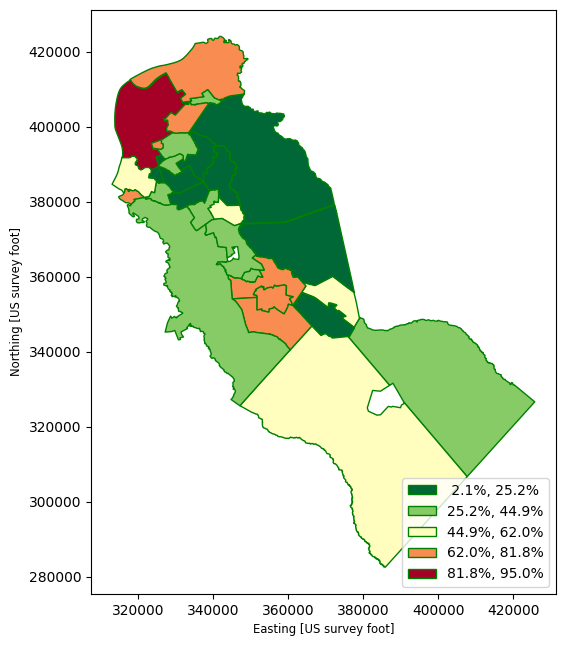

In [47]:
fig, ax = plt.subplots(1, figsize=(6,10))
ed1.plot(ax=ax, column='Economically Disadvantaged Students', legend=True, cmap='RdYlGn_r',
        scheme='naturalbreaks', k=5, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.1f}%", 'loc': 'lower right', 'markerscale': 1.4})
ed2.plot(ax=ax, column='Economically Disadvantaged Students', cmap='RdYlGn_r',
        scheme='naturalbreaks', k=5, edgecolor='green', linewidth=1)


In [48]:
#For School Year 2023-2024
#Rename columns, only include 23-24 School Year, make upper case and strip white space, split Muni into first word only
DisXls2324=DisXls[DisXls['SchoolYear'] =='2023-24'][['CountyName','DistrictCode','District','Economically Disadvantaged Students']]
DisXls2324

,CountyName,DistrictCode,District,Economically Disadvantaged Students
3,Camden,0150,AUDUBON,19.7
8,Camden,0190,BARRINGTON,35.5
13,Camden,0260,BELLMAWR,47.4
18,Camden,0330,BERLIN BOROUGH,17.2
23,Camden,0340,BERLIN TOWNSHIP,36.4
28,Camden,0390,BLACK HORSE PIKE,34.3
33,Camden,0580,BROOKLAWN,67.3
38,Camden,0680,CAMDEN CITY,54.7
43,Camden,0700,CAMDEN COUNTY TECHNICAL,50.2
48,Camden,0800,CHERRY HILL,18.1


In [49]:
ed3 = pd.merge(njrhs2, DisXls2324, left_on=['District'], right_on=['District'], how='outer', indicator=True)
ed3.columns
ed3[['GEOID','District','CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry',
       'CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,Economically Disadvantaged Students,_merge
0,NaN,AUDUBON,Camden,0150,19.7,right_only
1,NaN,BARRINGTON,Camden,0190,35.5,right_only
2,NaN,BELLMAWR,Camden,0260,47.4,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,17.2,right_only
4,NaN,BERLIN TOWNSHIP,Camden,0340,36.4,right_only
5,3401770,BLACK HORSE PIKE,Camden,0390,34.3,both
6,NaN,BROOKLAWN,Camden,0580,67.3,right_only
7,NaN,CAMDEN CITY,Camden,0680,54.7,right_only
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,50.2,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,59.5,right_only


In [50]:
ed3._merge.value_counts()

,count
_merge,
right_only,39
both,3
left_only,0


In [51]:
ed4 = pd.merge(njsch2, DisXls2324, left_on=['District'], right_on=['District'], how='outer', indicator=True)
ed4.columns
ed4[['GEOID','District','CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry',
       'CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,Economically Disadvantaged Students,_merge
0,3401050,AUDUBON,Camden,0150,19.7,both
1,3401170,BARRINGTON,Camden,0190,35.5,both
2,NaN,BELLMAWR,Camden,0260,47.4,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,17.2,right_only
4,3401620,BERLIN TOWNSHIP,Camden,0340,36.4,both
5,NaN,BLACK HORSE PIKE,Camden,0390,34.3,right_only
6,3402370,BROOKLAWN,Camden,0580,67.3,both
7,3402640,CAMDEN CITY,Camden,0680,54.7,both
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,50.2,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,59.5,right_only


In [52]:
ed4._merge.value_counts()

,count
_merge,
both,23
right_only,19
left_only,2


In [53]:
#For School Year 2022-2023
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls2223=DisXls[DisXls['SchoolYear'] =='2022-23'][['CountyName','DistrictCode','District','Economically Disadvantaged Students']]
DisXls2223

,CountyName,DistrictCode,District,Economically Disadvantaged Students
2,Camden,0150,AUDUBON,20.3
7,Camden,0190,BARRINGTON,25.9
12,Camden,0260,BELLMAWR,43.9
17,Camden,0330,BERLIN BOROUGH,11.3
22,Camden,0340,BERLIN TOWNSHIP,41.4
27,Camden,0390,BLACK HORSE PIKE,31.3
32,Camden,0580,BROOKLAWN,65.0
37,Camden,0680,CAMDEN CITY,54.5
42,Camden,0700,CAMDEN COUNTY TECHNICAL,49.5
47,Camden,0800,CHERRY HILL,18.8


In [54]:
ed5 = pd.merge(njrhs2, DisXls2223, left_on=['District'], right_on=['District'], how='outer', indicator=True)
ed5.columns
ed5[['GEOID','District','CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry',
       'CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,Economically Disadvantaged Students,_merge
0,NaN,AUDUBON,Camden,0150,20.3,right_only
1,NaN,BARRINGTON,Camden,0190,25.9,right_only
2,NaN,BELLMAWR,Camden,0260,43.9,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,11.3,right_only
4,NaN,BERLIN TOWNSHIP,Camden,0340,41.4,right_only
5,3401770,BLACK HORSE PIKE,Camden,0390,31.3,both
6,NaN,BROOKLAWN,Camden,0580,65.0,right_only
7,NaN,CAMDEN CITY,Camden,0680,54.5,right_only
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,49.5,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,85.6,right_only


In [55]:
ed5._merge.value_counts()

,count
_merge,
right_only,39
both,3
left_only,0


In [56]:
ed6= pd.merge(njsch2, DisXls2223, left_on=['District'], right_on=['District'], how='outer', indicator=True)
ed6.columns
ed6[['GEOID','District','CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry',
       'CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,Economically Disadvantaged Students,_merge
0,3401050,AUDUBON,Camden,0150,20.3,both
1,3401170,BARRINGTON,Camden,0190,25.9,both
2,NaN,BELLMAWR,Camden,0260,43.9,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,11.3,right_only
4,3401620,BERLIN TOWNSHIP,Camden,0340,41.4,both
5,NaN,BLACK HORSE PIKE,Camden,0390,31.3,right_only
6,3402370,BROOKLAWN,Camden,0580,65.0,both
7,3402640,CAMDEN CITY,Camden,0680,54.5,both
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,49.5,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,85.6,right_only


In [57]:
ed6._merge.value_counts()

,count
_merge,
both,23
right_only,19
left_only,2


### **MAPS OF LAST 3 YEARS OF ECNOMICAL DISADVANTAGED STUDENTS SIDE BY SIDE**

Map shows possible funding for distressed areas in 2023 - 2024 however not sufficient the following year, 2024 - 2025 as economic disadvantage increased after decreasing previous year.

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

[]

[]

Text(0.5, 179.49366202728203, 'Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Dollars)')

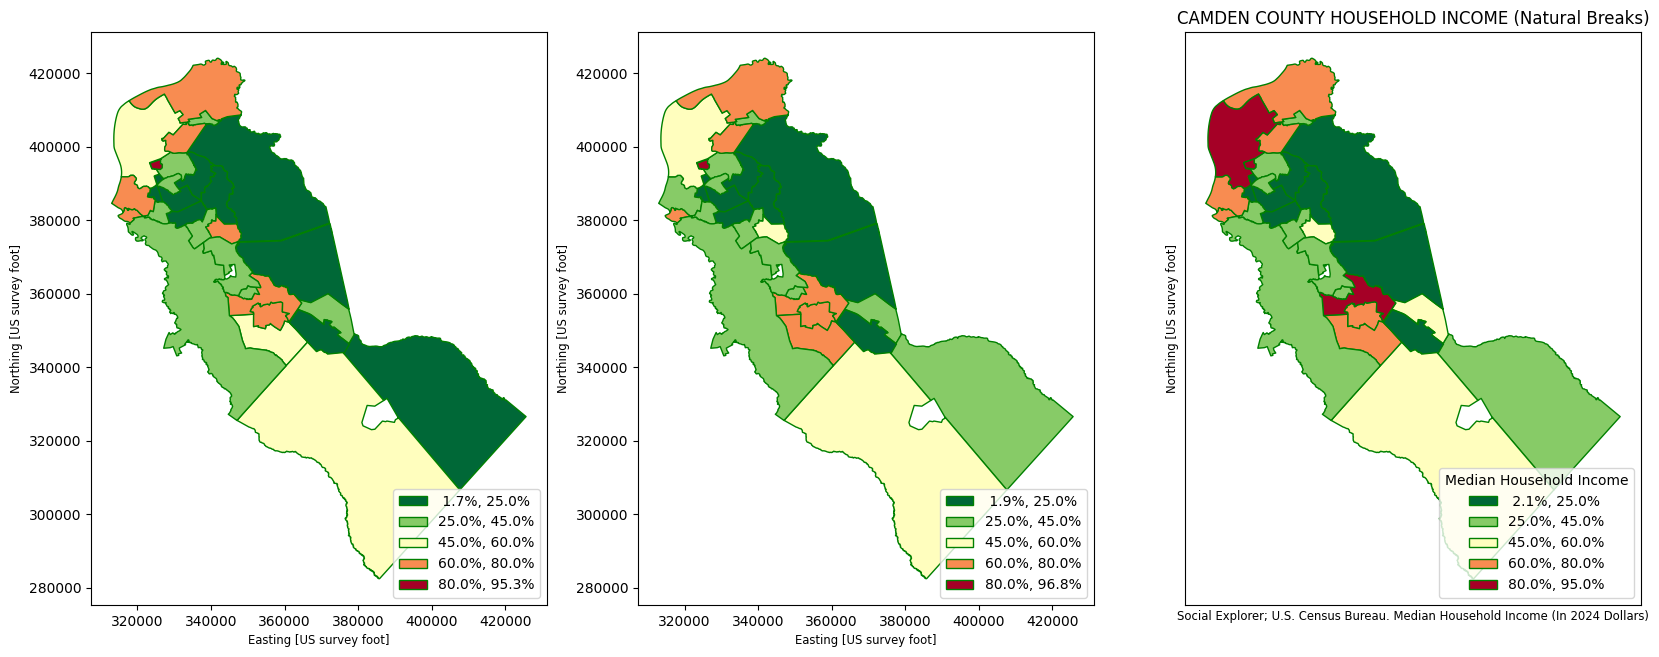

In [58]:
fig, axs = plt.subplots(1, 3, figsize=(20, 10))
# Left plot (Natural Breaks)2023-2024
ed6.plot(ax=axs[0], column='Economically Disadvantaged Students', legend=True, cmap='RdYlGn_r',
        scheme='UserDefined', classification_kwds={'bins': [25, 45, 60, 80]}, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.1f}%", 'loc': 'lower right', 'markerscale': 1.4})
ed5.plot(ax=axs[0], column='Economically Disadvantaged Students', cmap='RdYlGn_r',
        scheme='UserDefined', classification_kwds={'bins': [25, 45, 60, 80]}, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.1f}%", 'loc': 'lower right', 'markerscale': 1.4})

# Middle plot (Natural Breaks)2024-2025
ed4.plot(ax=axs[1], column='Economically Disadvantaged Students', legend=True, cmap='RdYlGn_r',
        scheme='UserDefined', classification_kwds={'bins': [25, 45, 60, 80]}, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.1f}%", 'loc': 'lower right', 'markerscale': 1.4})
ed3.plot(ax=axs[1], column='Economically Disadvantaged Students', cmap='RdYlGn_r',
        scheme='UserDefined', classification_kwds={'bins': [25, 45, 60, 80]}, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.1f}%", 'loc': 'lower right', 'markerscale': 1.4})

# Last plot (Natural Breaks)2025-2026
ed1.plot(ax=axs[2], column='Economically Disadvantaged Students', legend=True, cmap='RdYlGn_r',
        scheme='UserDefined', classification_kwds={'bins': [25, 45, 60, 80]}, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.1f}%", 'loc': 'lower right', 'markerscale': 1.4})
ed2.plot(ax=axs[2], column='Economically Disadvantaged Students', cmap='RdYlGn_r',
        scheme='UserDefined', classification_kwds={'bins': [25, 45, 60, 80]}, edgecolor='green', linewidth=1)

leg = axs[2].get_legend()
if leg is not None:
    leg.set_title("Median Household Income")
axs[2].title.set_text("CAMDEN COUNTY HOUSEHOLD INCOME (Natural Breaks)")
axs[2].set_xticks([])
axs[2].set_yticks([])
axs[2].set_xlabel("Social Explorer; U.S. Census Bureau. Median Household Income (In 2024 Dollars)")

2024 - 2025 Economic Disadvantaged Students map similar to Google search,
https://www.google.com/search?sca_esv=5b7f624190c766d8&rlz=1C1GCEA_enUS1235US1235&sxsrf=APpeQntU3iwEXsV9wxzAYXlsELOIfYDntQ:1791497138264&udm=2&fbs=ABfTbFVyMZGZf1hfvX9uKjN_-G8cY2oODYyTyZk24Xz37_7FQzcgMAXI6mDl4aLs1WJDXE-FPuVUjVB9_WO7OnpH1X7GhGoNVLROZYTxoyoqEaYuHt2NXUXO98OQTt-V2TvGCXckM2gQnUPwDRBfA-v8aogobWJe_jZQ-TcHGlO4AYGENKz-G-82f9RArff3CkNo0dCMTsjtQMqNUM69iypP9di51keTUg&q=percent+of+economically+disadvantaged+students+by+municipalities+camden+county+nj&sa=X&ved=2ahUKEwikkKr0tquXAxUVEVkFHTYNB-kQtKgLegQIGRAB&biw=1280&bih=551&dpr=1.5#sv=CAMSUxoyKhBlLU94c2hLSm45OVc5M29NMg5PeHNoS0puOTlXOTNvTToOMGFmM3RFcmgxZk80QU0gBCoXCgFzEhBlLU94c2hLSm45OVc5M29NGAEwAVACGAcgztq65QJKCBACGAEgAigB

### **IN-SCHOOL BEHAVIORAL INCIDENTS**
Analyzing youth behavior in relation to lack of after school programs

In [59]:
#in-school incidents involving violence, weapons, substance abuse and vandalism
#Downloadable data regarding school performance
#https://www.nj.gov/education/spr/download/
BehXls=pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School%20Incidents.xlsx', header = 3)

In [60]:
BehXls.dtypes

,0
CountyCode,object
CountyName,object
DistrictCode,object
DistrictName,object
SchoolYear,object
Violence,float64
Weapons,float64
Vandalism,float64
Substances,float64
HIB,float64


In [61]:
##identify headings of Excel file
BehXls.head(3)

,CountyCode,CountyName,DistrictCode,DistrictName,SchoolYear,Violence,Weapons,Vandalism,Substances,HIB,TotalUniqueIncidents,IncidentsPer100Students
0,01,Atlantic,0010,Absecon Public Schools District,2024-25,1.0,0.0,0.0,0.0,5.0,6.0,0.64
1,01,Atlantic,0110,Atlantic City School District,2024-25,130.0,12.0,4.0,36.0,22.0,204.0,3.17
2,01,Atlantic,0120,Atlantic County Vocational School District,2024-25,2.0,0.0,2.0,10.0,2.0,16.0,0.89


In [62]:
#Rename columns
BehXls.rename(columns={'DistrictName' : 'District'}, inplace=True)
BehXls['District'] = BehXls['District'].str.upper()
BehXls['District'] = BehXls['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
BehXls['District'] = BehXls['District'].str.replace("LAWNSIDET", "LAWNSIDE")
BehXls["District"] = BehXls["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
BehXls["District"] = BehXls["District"].str.replace(" REGIONAL", "")
BehXls["District"] = BehXls["District"].str.replace(" SCHOOL DISTRICT", "")
BehXls["District"] = BehXls["District"].str.replace(" BOARD OF EDUCATION", "")
BehXls["District"] = BehXls["District"].str.replace(" PUBLIC SCHOOLS", "")

BehXls

,CountyCode,CountyName,DistrictCode,District,SchoolYear,Violence,Weapons,Vandalism,Substances,HIB,TotalUniqueIncidents,IncidentsPer100Students
0,01,Atlantic,0010,ABSECON DISTRICT,2024-25,1.0,0.0,0.0,0.0,5.0,6.0,0.64
1,01,Atlantic,0110,ATLANTIC CITY,2024-25,130.0,12.0,4.0,36.0,22.0,204.0,3.17
2,01,Atlantic,0120,ATLANTIC COUNTY VOCATIONAL,2024-25,2.0,0.0,2.0,10.0,2.0,16.0,0.89
3,01,Atlantic,0125,ATLANTIC COUNTY SPECIAL SERVICES,2024-25,2.0,0.0,0.0,0.0,4.0,6.0,1.72
4,01,Atlantic,0570,BRIGANTINE,2024-25,0.0,0.0,0.0,0.0,2.0,2.0,0.53
...,...,...,...,...,...,...,...,...,...,...,...,...
663,80,Morris,8050,UNITY CHARTER SCHOOL,2024-25,0.0,0.0,0.0,0.0,0.0,0.0,0.00
664,80,Hudson,8060,UNIVERSITY ACADEMY CHARTER HIGH SCHOOL,2024-25,23.0,2.0,2.0,7.0,0.0,34.0,8.15
665,80,Mercer,8140,THE VILLAGE CHARTER SCHOOL,2024-25,11.0,0.0,0.0,3.0,2.0,16.0,4.40
666,State,State,State,STATE,2024-25,12730.0,902.0,1793.0,7198.0,7456.0,29826.0,2.13


In [63]:
BehXls2425 = BehXls[(BehXls['SchoolYear'] == '2024-25') & (BehXls['CountyName'] == 'Camden')][['DistrictCode', 'District', 'IncidentsPer100Students']]
BehXls2425

,DistrictCode,District,IncidentsPer100Students
139,0150,AUDUBON,1.27
140,0190,BARRINGTON,0.38
141,0260,BELLMAWR,0.17
142,0330,BERLIN BOROUGH,1.99
143,0340,BERLIN TOWNSHIP,1.94
144,0390,BLACK HORSE PIKE,3.35
145,0580,BROOKLAWN,1.72
146,0680,CAMDEN CITY,4.33
147,0700,CAMDEN COUNTY TECHNICAL,2.80
148,0800,CHERRY HILL,1.62


In [64]:
b1 = pd.merge(njrhs2, BehXls2425, left_on=['District'], right_on=['District'], how='outer', indicator=True)
b1

,DistrictCode_x,CountyCode,District,GEOID,geometry,DistrictCode_y,IncidentsPer100Students,_merge
0,NaN,NaN,AUDUBON,NaN,None,0150,1.27,right_only
1,NaN,NaN,BARRINGTON,NaN,None,0190,0.38,right_only
2,NaN,NaN,BELLMAWR,NaN,None,0260,0.17,right_only
3,NaN,NaN,BERLIN BOROUGH,NaN,None,0330,1.99,right_only
4,NaN,NaN,BERLIN TOWNSHIP,NaN,None,0340,1.94,right_only
5,0390,07,BLACK HORSE PIKE,3401770,"POLYGON ((322014.45 380972.53, 321992.84 38092...",0390,3.35,both
6,NaN,NaN,BROOKLAWN,NaN,None,0580,1.72,right_only
7,NaN,NaN,CAMDEN CITY,NaN,None,0680,4.33,right_only
8,NaN,NaN,CAMDEN COUNTY TECHNICAL,NaN,None,0700,2.80,right_only
9,NaN,NaN,"CAMDEN PREP, INC.",NaN,None,1801,5.34,right_only


In [65]:
b1._merge.value_counts()

,count
_merge,
right_only,39
both,3
left_only,0


In [66]:
b2 = pd.merge(njsch2, BehXls2425, left_on=['District'], right_on=['District'], how='outer', indicator=True)
b2

,DistrictCode_x,CountyCode,District,GEOID,geometry,DistrictCode_y,IncidentsPer100Students,_merge
0,0150,07,AUDUBON,3401050,"POLYGON ((333599.519 389532.256, 334908.018 38...",0150,1.27,both
1,0190,07,BARRINGTON,3401170,"POLYGON ((341374.86 382055.06, 341383.46 38191...",0190,0.38,both
2,NaN,NaN,BELLMAWR,NaN,None,0260,0.17,right_only
3,NaN,NaN,BERLIN BOROUGH,NaN,None,0330,1.99,right_only
4,0340,07,BERLIN TOWNSHIP,3401620,"POLYGON ((374626.851 357935.944, 375096.547 35...",0340,1.94,both
5,NaN,NaN,BLACK HORSE PIKE,NaN,None,0390,3.35,right_only
6,0580,07,BROOKLAWN,3402370,"POLYGON ((321421.382 381045.717, 321229.38 381...",0580,1.72,both
7,0680,07,CAMDEN CITY,3402640,"POLYGON ((329538.15 410361.33, 329670.85 41012...",0680,4.33,both
8,NaN,NaN,CAMDEN COUNTY TECHNICAL,NaN,None,0700,2.80,right_only
9,NaN,NaN,"CAMDEN PREP, INC.",NaN,None,1801,5.34,right_only


In [67]:
b2._merge.value_counts()

,count
_merge,
both,23
right_only,19
left_only,2


### **MAPS OF ECNOMICAL DISADVANTAGED STUDENTS AND SCHOOL INCIDENTS 2024 - 2025 SCHOOL YEAR, SIDE BY SIDE**

Economic disadvantaged students aand school incidents are very similar showing possible correlation for 2024-2025

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

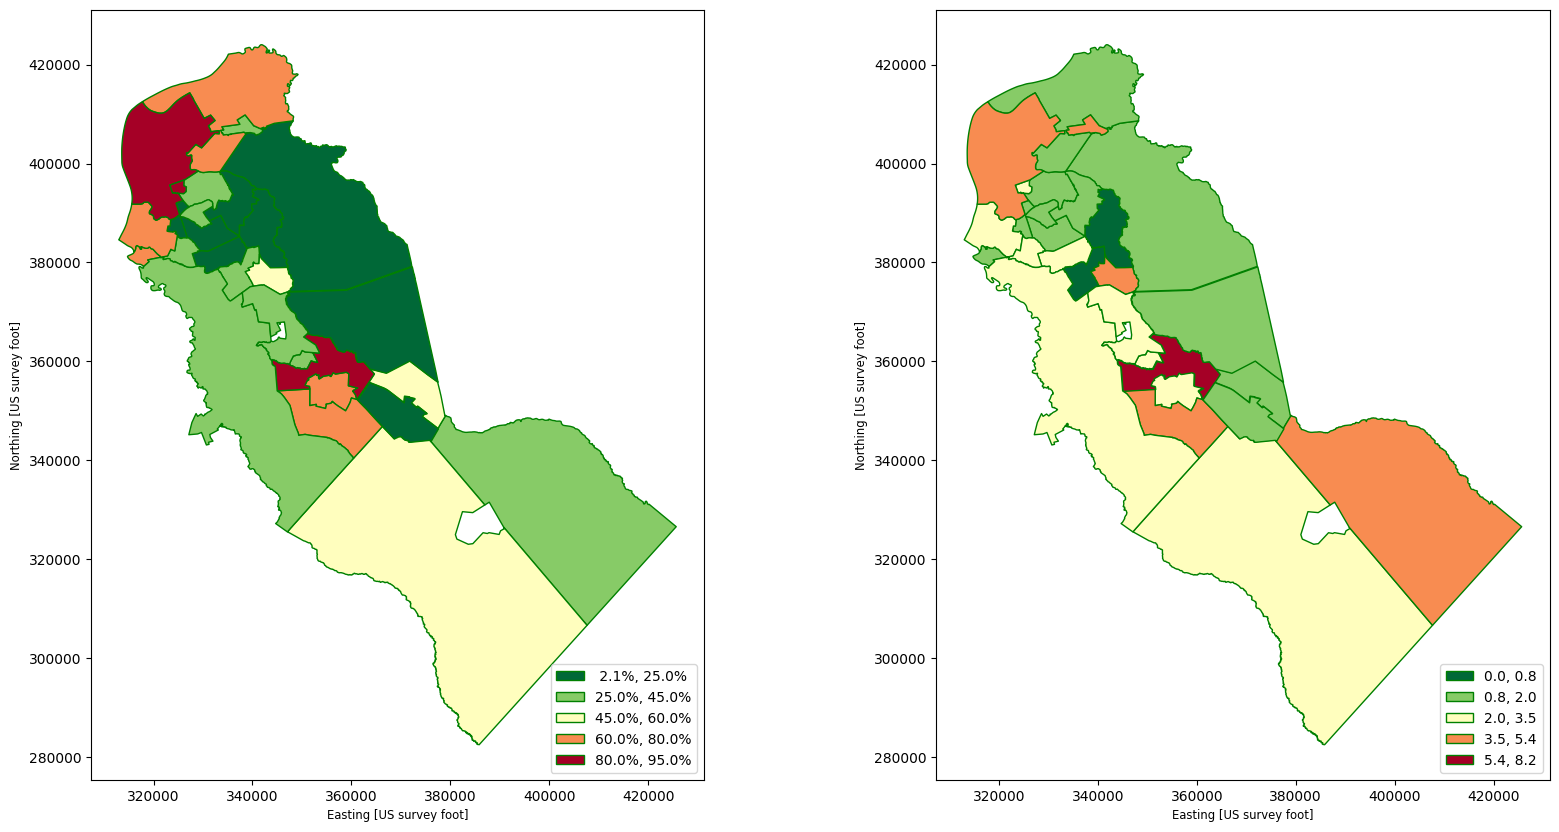

In [68]:
fig, axs = plt.subplots(1, 2, figsize=(20, 10))
ed1.plot(ax=axs[0], column='Economically Disadvantaged Students', legend=True, cmap='RdYlGn_r',
        scheme='UserDefined', classification_kwds={'bins': [25, 45, 60, 80]}, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.1f}%", 'loc': 'lower right', 'markerscale': 1.4})
ed2.plot(ax=axs[0], column='Economically Disadvantaged Students', cmap='RdYlGn_r',
        scheme='UserDefined', classification_kwds={'bins': [25, 45, 60, 80]}, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.1f}%", 'loc': 'lower right', 'markerscale': 1.4})

b2.plot(ax=axs[1], column='IncidentsPer100Students', legend=True, cmap='RdYlGn_r',
        scheme='naturalbreaks', k=5, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.1f}", 'loc': 'lower right', 'markerscale': 1.4})
b1.plot(ax=axs[1], column='IncidentsPer100Students', cmap='RdYlGn_r',
        scheme='naturalbreaks', k=5, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.1f}", 'loc': 'lower right', 'markerscale': 1.4})

### **ABSENTEEISM**
Analyzing youth behavior in relation to lack of after school programs

In [69]:
#in-school incidents involving violence, weapons, substance abuse and vandalism
#Downloadable data regarding school performance
#https://www.nj.gov/education/spr/download/
AbsXls=pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Chronic%20Absenteeism%20by%20Grade.xlsx', header = 3)

In [70]:
AbsXls.head(3)

,CountyCode,CountyName,DistrictCode,DistrictName,SchoolYear,Grade,ChronicAbsenteeismRate_District,ChronicAbsenteeismRate_State
0,01,Atlantic,0010,Absecon Public Schools District,2024-25,Grade 1,18.7%,14.3%
1,01,Atlantic,0010,Absecon Public Schools District,2024-25,Grade 2,6.9%,12.7%
2,01,Atlantic,0010,Absecon Public Schools District,2024-25,Grade 3,12.7%,11.6%


In [71]:
from abc import abstractclassmethod
# 1. Rename columns, make everything upper case and clear white space
AbsXls.rename(columns={'DistrictName': 'District'}, inplace=True)
AbsXls['District'] = AbsXls['District'].str.upper()
AbsXls["District"] = AbsXls["District"].str.replace(" SCHOOL DISTRICT", "")
AbsXls['District'] = AbsXls['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
AbsXls['District'] = AbsXls['District'].str.replace(" BOARD OF EDUCATION", "")
AbsXls['District'] = AbsXls['District'].str.replace(" PUBLIC", "")
AbsXls['District'] = AbsXls['District'].str.replace(" REGIONAL", "")
AbsXls['District'] = AbsXls['District'].str.strip()

# 2. Filter for high school grades in Camden County
grades_to_keep = ['Grade 9', 'Grade 10', 'Grade 11', 'Grade 12']
Abs912 = AbsXls[AbsXls['Grade'].isin(grades_to_keep) & (AbsXls['CountyName'] == 'Camden')]

# 3. Convert absenteeism rate to numeric float for calculation
Abs912['ChronicAbsenteeismRate_District'] = Abs912['ChronicAbsenteeismRate_District'].astype(str).str.replace('%', '').str.strip()
Abs912['ChronicAbsenteeismRate_District'] = pd.to_numeric(Abs912['ChronicAbsenteeismRate_District'], errors='coerce')

# 4. Group grades together as 1 average rate per municipality
Abs912 = Abs912.groupby(['DistrictCode', 'District'], as_index=False)['ChronicAbsenteeismRate_District'].mean()

# 5. Extract first word safely from the grouped result
Abs912

/tmp/ipykernel_670/1424239705.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Abs912['ChronicAbsenteeismRate_District'] = Abs912['ChronicAbsenteeismRate_District'].astype(str).str.replace('%', '').str.strip()
/tmp/ipykernel_670/1424239705.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Abs912['ChronicAbsenteeismRate_District'] = pd.to_numeric(Abs912['ChronicAbsenteeismRate_District'], errors='coerce')


,DistrictCode,District,ChronicAbsenteeismRate_District
0,0150,AUDUBON,12.250
1,0390,BLACK HORSE PIKE,6.625
2,0680,CAMDEN CITY,56.675
3,0700,CAMDEN COUNTY TECHNICAL,9.800
4,0800,CHERRY HILL,16.875
5,0940,COLLINGSWOOD,17.250
6,1255,EASTERN CAMDEN COUNTY,16.425
7,1770,GLOUCESTER CITY,22.825
8,1799,"KIPP: COOPER NORCROSS, A NEW JERSEY NONPROFIT ...",62.100
9,1801,"CAMDEN PREP, INC.",69.000


In [72]:
#merged newly created column "first_word_Muni"
ab1 = pd.merge(njrhs2, Abs912, left_on=['District'], right_on=['District'], how='outer', indicator=True)
ab1

,DistrictCode_x,CountyCode,District,GEOID,geometry,DistrictCode_y,ChronicAbsenteeismRate_District,_merge
0,NaN,NaN,AUDUBON,NaN,None,0150,12.250,right_only
1,0390,07,BLACK HORSE PIKE,3401770,"POLYGON ((322014.45 380972.53, 321992.84 38092...",0390,6.625,both
2,NaN,NaN,CAMDEN CITY,NaN,None,0680,56.675,right_only
3,NaN,NaN,CAMDEN COUNTY TECHNICAL,NaN,None,0700,9.800,right_only
4,NaN,NaN,"CAMDEN PREP, INC.",NaN,None,1801,69.000,right_only
5,NaN,NaN,CAMDEN'S PROMISE CHARTER SCHOOL,NaN,None,6107,12.950,right_only
6,NaN,NaN,CHERRY HILL,NaN,None,0800,16.875,right_only
7,NaN,NaN,COLLINGSWOOD,NaN,None,0940,17.250,right_only
8,1255,07,EASTERN CAMDEN COUNTY,3404380,"MULTIPOLYGON (((367503.372 354073.834, 370576....",1255,16.425,both
9,NaN,NaN,GLOUCESTER CITY,NaN,None,1770,22.825,right_only


In [73]:
ab1._merge.value_counts()

,count
_merge,
right_only,18
both,3
left_only,0


In [74]:
#merged newly created column "first_word_Muni"
ab2 = pd.merge(njsch2, Abs912, left_on=['District'], right_on=['District'], how='outer', indicator=True)
ab2

,DistrictCode_x,CountyCode,District,GEOID,geometry,DistrictCode_y,ChronicAbsenteeismRate_District,_merge
0,0150,07,AUDUBON,3401050,"POLYGON ((333599.519 389532.256, 334908.018 38...",0150,12.250,both
1,0190,07,BARRINGTON,3401170,"POLYGON ((341374.86 382055.06, 341383.46 38191...",NaN,NaN,left_only
2,0340,07,BERLIN TOWNSHIP,3401620,"POLYGON ((374626.851 357935.944, 375096.547 35...",NaN,NaN,left_only
3,NaN,NaN,BLACK HORSE PIKE,NaN,None,0390,6.625,right_only
4,0580,07,BROOKLAWN,3402370,"POLYGON ((321421.382 381045.717, 321229.38 381...",NaN,NaN,left_only
5,0680,07,CAMDEN CITY,3402640,"POLYGON ((329538.15 410361.33, 329670.85 41012...",0680,56.675,both
6,NaN,NaN,CAMDEN COUNTY TECHNICAL,NaN,None,0700,9.800,right_only
7,NaN,NaN,"CAMDEN PREP, INC.",NaN,None,1801,69.000,right_only
8,NaN,NaN,CAMDEN'S PROMISE CHARTER SCHOOL,NaN,None,6107,12.950,right_only
9,0800,07,CHERRY HILL,3403000,"POLYGON ((347458.19 406942.14, 347464.79 40692...",0800,16.875,both


In [75]:
ab2._merge.value_counts()

,count
_merge,
left_only,13
both,12
right_only,9


### **CENTROID THEMATIC MAP OF CHRONIC ABSENTEEISM**

Most schools did not have stats however schools that did were expected to have high absenteeism in economically disadvanted communities.

In [76]:
ab1["geometry"] = ab1["geometry"].centroid
ab2["geometry"] = ab2["geometry"].centroid

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

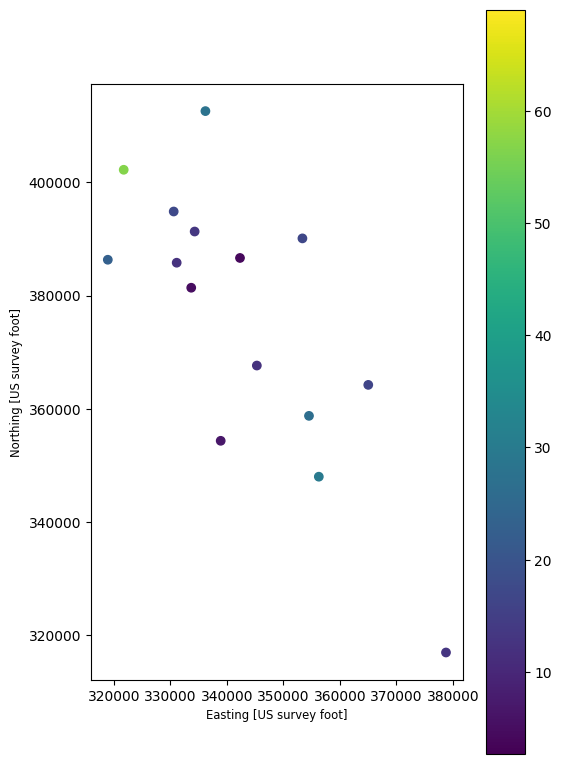

In [77]:
fig, ax = plt.subplots(1, figsize=(6,10))
ab1.plot(ax=ax, column='ChronicAbsenteeismRate_District')
ab2.plot(ax=ax, column='ChronicAbsenteeismRate_District', legend=True)

### **OVERLAY MAP OF CHRONIC ABSENTEEISM & ECONOMIC DISADVANTAGED COMMUNITIES**

Most schools did not have stats however schools that did were expected to have high absenteeism in economically disadvanted communities.

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

[]

[]

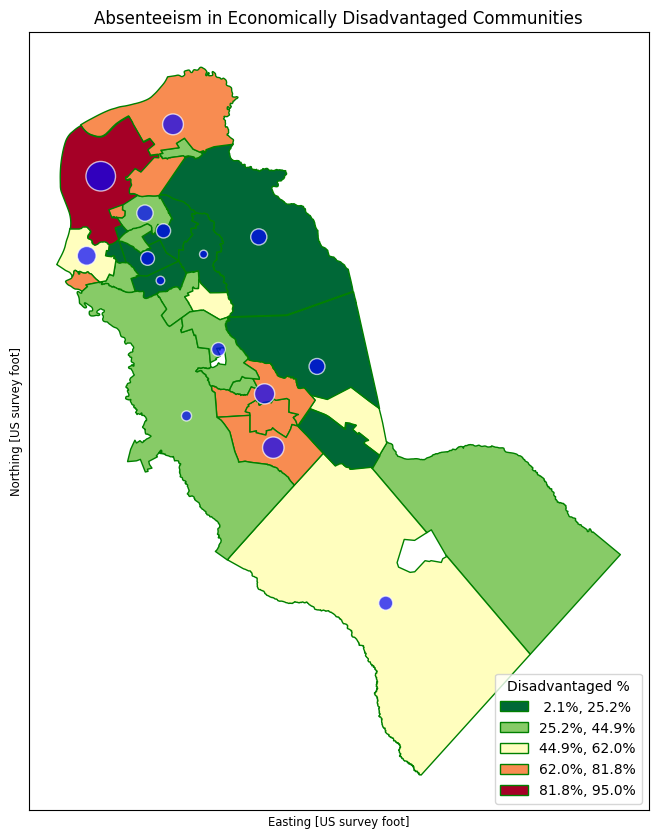

In [78]:
fig, ax = plt.subplots(1, figsize=(8,12))

# 1. Base Map: Economically Disadvantaged Students (Unified)
ed1.plot(ax=ax, column='Economically Disadvantaged Students', legend=True, cmap='RdYlGn_r',
        scheme='naturalbreaks', k=5, edgecolor='green', linewidth=1,
        legend_kwds={"fmt": "{:,.1f}%", 'loc': 'lower right', 'markerscale': 1.4})

# 2. Base Map: Economically Disadvantaged Students (Secondary)
ed2.plot(ax=ax, column='Economically Disadvantaged Students', cmap='RdYlGn_r',
        scheme='naturalbreaks', k=5, edgecolor='green', linewidth=1)

l1 = ax.get_legend()
if l1 is not None:
    l1.set_title('Disadvantaged %')

# 3. Overlay Points: Chronic Absenteeism (ab1 and ab2 centroids) scaled by rate
if 'ChronicAbsenteeismRate_District' in ab1.columns:
    ab1_sizes = ab1['ChronicAbsenteeismRate_District'].fillna(0) * 8
    ab1.plot(ax=ax, color='blue', edgecolor='white', linewidth=1,
             markersize=ab1_sizes, alpha=0.7, label='Absenteeism (Sec)')

if 'ChronicAbsenteeismRate_District' in ab2.columns:
    ab2_sizes = ab2['ChronicAbsenteeismRate_District'].fillna(0) * 8
    ab2.plot(ax=ax, linewidth=1, legend=True, color='blue', edgecolor='white',
             markersize=ab2_sizes, alpha=0.7, label='Absenteeism (Uni)')

ax.title.set_text("Absenteeism in Economically Disadvantaged Communities")
ax.set_xticks([]); ax.set_yticks([])
plt.show()

### **SPENDING PER STUDENT**
Identifying spending per student helps determine resource needs

In [79]:
SpeXls =pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Detail_FY24.xlsx', header = 2)

In [80]:
SpeXls.head ()

,County,District Name,District Code,General Current Expense Per Pupil,Total Capital Outlay Per Pupil,Total Grants & Entitlements Per Pupil,Total Food Services \nPer Pupil,Debt Service on Locally Issued Bonds Per Pupil,Debt Service On School Development Authority Bonds Per Pupil,Total Spending,Daily Enrollment Plus Sent Pupils,Calculated Per Pupil Amount
0,Atlantic,Absecon City,10.0,20552.748734,909.568389,3725.891591,731.407295,409.245187,140.775218,2.612553e+07,987.000000,26470.0
1,Atlantic,Atlantic City,110.0,28188.935342,592.287448,7705.869504,1159.238766,782.381047,61.597791,2.477869e+08,6437.644444,38490.0
2,Atlantic,Atlantic Co Vocational,120.0,21504.480837,452.288131,2891.471689,777.948112,1833.721010,13.626076,4.868829e+07,1772.188889,27474.0
3,Atlantic,Atlantic Co Special Serv,125.0,59401.999084,1724.889364,639.475050,1398.272547,0.000000,2550.904044,2.153170e+07,327.650000,65716.0
4,Atlantic,Brigantine City,570.0,43935.419393,6343.836731,5081.115948,428.304310,1322.427127,446.855281,2.365120e+07,410.911111,57558.0


In [81]:
SpeXls.dtypes

,0
County,object
District Name,object
District Code,float64
General Current Expense Per Pupil,float64
Total Capital Outlay Per Pupil,float64
Total Grants & Entitlements Per Pupil,float64
Total Food Services \nPer Pupil,float64
Debt Service on Locally Issued Bonds Per Pupil,float64
Debt Service On School Development Authority Bonds Per Pupil,float64
Total Spending,float64


In [82]:
SpeXls = SpeXls[SpeXls['County'] == 'Camden']
SpeXls.rename(columns={'District Name': 'District'}, inplace=True)
SpeXls['District'] = SpeXls['District'].str.upper()
SpeXls['District'] = SpeXls['District'].str.replace(" PUBLIC SCHOOL DISTRICT", "")
SpeXls["District"] = SpeXls["District"].str.replace(" REGIONAL", "")
SpeXls["District"] = SpeXls["District"].str.replace(" TWP", "")
SpeXls["District"] = SpeXls["District"].str.replace(" REG", "")
SpeXls["District"] = SpeXls["District"].str.replace(" HIGH SCHOOL DIST", "")
SpeXls["District"] = SpeXls["District"].str.replace(" PUBLIC", "")
SpeXls["District"] = SpeXls["District"].str.replace(" BORO", "")
SpeXls["District"] = SpeXls["District"].str.replace(" TWP", "")
SpeXls["District"] = SpeXls["District"].str.replace("WINSLOW", "WINSLOW TOWNSHIP")
SpeXls["District"] = SpeXls["District"].str.replace("WATERFORD", "WATERFORD TOWNSHIP")
SpeXls["District"] = SpeXls["District"].str.replace("PENNSAUKEN", "PENNSAUKEN TOWNSHIP")
SpeXls['District'] = SpeXls['District'].str.strip()
SpeXls

,County,District,District Code,General Current Expense Per Pupil,Total Capital Outlay Per Pupil,Total Grants & Entitlements Per Pupil,Total Food Services \nPer Pupil,Debt Service on Locally Issued Bonds Per Pupil,Debt Service On School Development Authority Bonds Per Pupil,Total Spending,Daily Enrollment Plus Sent Pupils,Calculated Per Pupil Amount
151,Camden,AUDUBON,150.0,23481.725246,539.325057,2793.702653,498.118256,1706.595282,399.333729,4.166928e+07,1416.416667,29419.0
152,Camden,BARRINGTON,190.0,24907.745663,589.448000,928.464334,403.467375,609.140143,346.948332,2.131990e+07,767.311111,27785.0
153,Camden,BELLMAWR,260.0,21216.559933,1213.259104,5132.792353,710.588362,191.173630,117.105028,3.386969e+07,1185.022222,28581.0
154,Camden,BERLIN,330.0,20103.087718,162.356238,918.444016,459.809974,858.730247,244.442151,1.907287e+07,838.483333,22747.0
155,Camden,BERLIN,340.0,24638.233195,809.684959,2260.271816,386.315479,372.130620,258.865711,2.329654e+07,811.005556,28726.0
156,Camden,BLACK HORSE PIKE,390.0,27478.436081,1272.767434,2174.166337,350.549534,0.000000,153.278390,1.107850e+08,3524.905556,31429.0
157,Camden,BROOKLAWN,580.0,22449.020929,347.764226,2208.447629,510.724693,4048.509326,430.072887,1.053358e+07,351.183333,29995.0
158,Camden,CAMDEN CITY,680.0,23130.632129,197.775632,18945.959997,1970.198734,0.000000,4854.599415,3.494107e+08,7116.427778,49099.0
159,Camden,CAMDEN COUNTY VOCATIONAL,700.0,24474.049015,865.562621,2073.034371,619.682816,0.000000,482.350060,6.167504e+07,2162.922652,28515.0
160,Camden,CHERRY HILL,800.0,25099.334787,1483.264066,1406.962784,340.865569,2101.044281,133.440280,3.290496e+08,10765.598901,30565.0


In [83]:
SpeXls['Calculated Per Pupil Amount'] = pd.to_numeric(SpeXls['Calculated Per Pupil Amount'], errors='coerce')

In [84]:
s1 = pd.merge(njrhs2, SpeXls, left_on=['District'], right_on=['District'], how='outer', indicator=True)
s1.columns
s1[['District','District Code', 'Calculated Per Pupil Amount', 'geometry', '_merge']]

Index(['DistrictCode', 'CountyCode', 'District', 'GEOID', 'geometry', 'County',
       'District Code', 'General Current Expense Per Pupil',
       'Total Capital Outlay Per Pupil',
       'Total Grants & Entitlements Per Pupil',
       'Total Food Services \nPer Pupil',
       'Debt Service on Locally Issued Bonds Per Pupil',
       'Debt Service On School Development Authority Bonds Per Pupil',
       'Total Spending', 'Daily Enrollment Plus Sent Pupils',
       'Calculated Per Pupil Amount', '_merge'],
      dtype='object')

,District,District Code,Calculated Per Pupil Amount,geometry,_merge
0,AUDUBON,150.0,29419.0,None,right_only
1,BARRINGTON,190.0,27785.0,None,right_only
2,BELLMAWR,260.0,28581.0,None,right_only
3,BERLIN,330.0,22747.0,None,right_only
4,BERLIN,340.0,28726.0,None,right_only
5,BLACK HORSE PIKE,390.0,31429.0,"POLYGON ((322014.45 380972.53, 321992.84 38092...",both
6,BROOKLAWN,580.0,29995.0,None,right_only
7,CAMDEN CITY,680.0,49099.0,None,right_only
8,CAMDEN COUNTY VOCATIONAL,700.0,28515.0,None,right_only
9,CAMDEN PREP,1801.0,25199.0,None,right_only


In [85]:
s1._merge.value_counts()

,count
_merge,
right_only,40
both,3
left_only,0


In [86]:
s2 = pd.merge(njsch2, SpeXls, left_on=['District'], right_on=['District'], how='outer', indicator=True)
s2.columns
s2[['District','District Code', 'Calculated Per Pupil Amount', 'geometry', '_merge']]

Index(['DistrictCode', 'CountyCode', 'District', 'GEOID', 'geometry', 'County',
       'District Code', 'General Current Expense Per Pupil',
       'Total Capital Outlay Per Pupil',
       'Total Grants & Entitlements Per Pupil',
       'Total Food Services \nPer Pupil',
       'Debt Service on Locally Issued Bonds Per Pupil',
       'Debt Service On School Development Authority Bonds Per Pupil',
       'Total Spending', 'Daily Enrollment Plus Sent Pupils',
       'Calculated Per Pupil Amount', '_merge'],
      dtype='object')

,District,District Code,Calculated Per Pupil Amount,geometry,_merge
0,AUDUBON,150.0,29419.0,"POLYGON ((333599.519 389532.256, 334908.018 38...",both
1,BARRINGTON,190.0,27785.0,"POLYGON ((341374.86 382055.06, 341383.46 38191...",both
2,BELLMAWR,260.0,28581.0,None,right_only
3,BERLIN,330.0,22747.0,None,right_only
4,BERLIN,340.0,28726.0,None,right_only
5,BERLIN TOWNSHIP,NaN,NaN,"POLYGON ((374626.851 357935.944, 375096.547 35...",left_only
6,BLACK HORSE PIKE,390.0,31429.0,None,right_only
7,BROOKLAWN,580.0,29995.0,"POLYGON ((321421.382 381045.717, 321229.38 381...",both
8,CAMDEN CITY,680.0,49099.0,"POLYGON ((329538.15 410361.33, 329670.85 41012...",both
9,CAMDEN COUNTY VOCATIONAL,700.0,28515.0,None,right_only


In [87]:
s2._merge.value_counts()

,count
_merge,
right_only,22
both,21
left_only,4


### **SCATTERPLOT OF INCIDENTS, ECONOMIC DISADVANTAGE AND SPENDING PER STUDENT**

Shows Lindenwold with high incidnets and economic disadvantage with a low median household income.  Camden City was to be expected to be the same as Lindenwold however did not expect Lindenwold to be higher than Camden City.

In [88]:
import plotly.express as px

# Combine the separate datasets into a single DataFrame for plotting
# We include SpeXls in the merge chain to get the 'Calculated Per Pupil Amount' column
merged_plot_df = Abs912.merge(BehXls2425, on='District') \
                       .merge(DisXls2425, on='District') \
                       .merge(SpeXls, on='District')

# Create the scatter plot using the merged DataFrame
px.scatter(
    merged_plot_df,
    x="Calculated Per Pupil Amount",
    y="IncidentsPer100Students",
    color="Economically Disadvantaged Students",
    color_continuous_scale='plasma_r',
    hover_data=['District'],
    width=750,
    height=600
)

px.scatter(
    merged_plot_df,
    x="Calculated Per Pupil Amount",
    y="ChronicAbsenteeismRate_District",
    color="Economically Disadvantaged Students",
    color_continuous_scale='plasma_r',
    hover_data=['District'],
    width=750,
    height=600
)